# Chapitre 8 - Exercices 8.7 à 8.11

Ces exercices portent sur la **synthèse vérifiée** (cours 2) et le **traitement** des
données (cours 3) :

- **8.7** : synthèse vérifiable de raisonnements avec Qwen2.5-0.5B : filtre par la
  réponse, auto-cohérence, coût par exemple gardé (mini-lab et calcul) ;
- **8.8** : un juge IA pour les données de préférence et son biais de position, avec la
  parade de NVIDIA (mini-lab) ;
- **8.9** : effondrement de modèle : demi-vie de la variance, point fixe avec données
  réelles, disparition des événements rares (calcul et simulation) ;
- **8.10** : dimensionner MinHash + LSH pour un milliard de documents (calcul et
  vérification) ;
- **8.11** : mise au format SFT : conversation multi-tours, masque de perte, bogues de
  template et d'espaces (mini-lab).

Les exercices 8.7 et 8.8 utilisent le GPU (Qwen2.5-0.5B et 1,5B, chargés l'un après
l'autre) ; les autres tournent sur CPU.

In [1]:
import warnings
from math import comb, log

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from aie import ch08_donnees as d8
from aie import llm
from aie.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                          annotate_bars, finish, set_style, subtitle)

warnings.filterwarnings("ignore")
set_style()
rng = np.random.default_rng(0)


def log_lisible(ax, axes="y"):
    """Graduations log au format décimal simple (sans exposants mathtext)."""
    from matplotlib.ticker import FuncFormatter, NullFormatter
    for a in axes:
        axis = ax.yaxis if a == "y" else ax.xaxis
        axis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
        axis.set_minor_formatter(NullFormatter())

## Exercice 8.7 : Synthèse vérifiable de raisonnements

**Énoncé.** On veut constituer un jeu de raisonnements pas à pas (CoT) pour des
problèmes arithmétiques, en faisant écrire les raisonnements par Qwen2.5-0.5B.

1. Générer un raisonnement glouton pour 16 problèmes produits par gabarit et ne garder
   que ceux dont la réponse finale est juste. Quel est le taux d'acceptation $p$ ?
2. **Auto-cohérence** : tirer 5 raisonnements à température 0,7 par problème. (a) Le
   vote majoritaire des réponses est-il plus souvent juste que le glouton ? (b) Sans
   vérité terrain, on garde un problème si au moins 3 réponses sur 5 concordent : quelle
   est la **précision** de ce filtre ?
3. Combien de générations faut-il pour obtenir 10 000 raisonnements vérifiés, et
   combien cela coûte-t-il si une génération de 200 tokens coûte $2 \times 10^{-4}$
   dollar ?

**Rappels.** Cours 2, section 6.1 et section *Data verification* du livre : on
synthétise d'abord ce que l'on sait vérifier ; la correction fonctionnelle (réponse
connue, exécution de tests) filtre les exemples. Une réponse finale juste n'implique pas
un raisonnement juste.

In [2]:
pbs = d8.make_word_problems(16, seed=7)
consigne = " Raisonne étape par étape puis termine par « Réponse : <nombre> »."
glouton = [d8.extract_number(llm.chat(p["question"] + consigne, llm.SMALL, max_new_tokens=220)) for p in pbs]
tirages = [[d8.extract_number(llm.chat(p["question"] + consigne, llm.SMALL, max_new_tokens=220,
                                       temperature=0.7, seed=100 + k)) for k in range(5)] for p in pbs]
llm.free_gpu()

lignes = []
for p, g, t in zip(pbs, glouton, tirages):
    vals = [v for v in t if v is not None]
    maj, nmaj = (pd.Series(vals).value_counts().index[0], pd.Series(vals).value_counts().iloc[0]) if vals else (None, 0)
    lignes.append({"attendu": p["answer"], "glouton": g, "tirages": t, "vote": maj, "accord (sur 5)": nmaj,
                   "glouton juste": g == p["answer"], "vote juste": maj == p["answer"],
                   "tirages justes": sum(v == p["answer"] for v in t)})
tab = pd.DataFrame(lignes)
tab[["attendu", "glouton", "tirages", "vote", "accord (sur 5)"]].head(8)

,attendu,glouton,tirages,vote,accord (sur 5)
0,26,-26,"[26, 26, 0, 3, 204]",26,2
1,143,143,"[133, 17, 46, 143, 396]",133,1
2,51,77,"[51, 43, 55, 47, 43]",43,2
3,25,26,"[39, 43, 15, 25, 25]",25,2
4,51,51,"[111, 51, 68, 18, 57]",111,1
5,96,96,"[138, 96, 5, 78, 36]",138,1
6,35,16,"[6, 53, 10, 65, None]",6,1
7,190,500,"[60, 190, 20, 61, 4]",60,1


**Solution.**

1. Taux d'acceptation (glouton) : p = 0.44
   Taux de réussite d'un tirage à T = 0,7 : 0.31
2a. Vote majoritaire sur 5 tirages : 0.50
2b. Filtre « au moins 3/5 concordent » : garde 19% des problèmes, précision 1.00


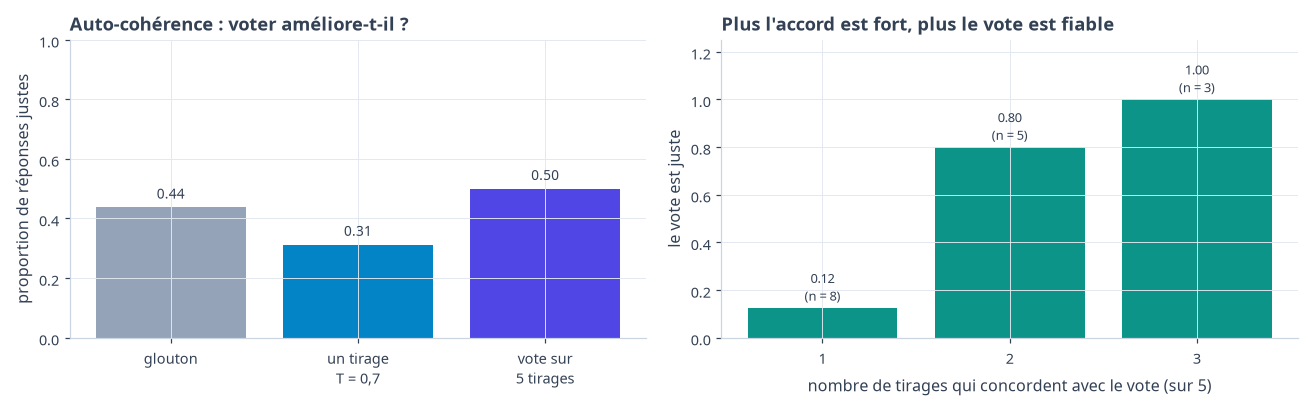

In [3]:
p_glouton = tab["glouton juste"].mean()
p_tirage = tab["tirages justes"].sum() / (5 * len(tab))
p_vote = tab["vote juste"].mean()
garde = tab["accord (sur 5)"] >= 3
precision = tab.loc[garde, "vote juste"].mean() if garde.any() else np.nan
print(f"1. Taux d'acceptation (glouton) : p = {p_glouton:.2f}")
print(f"   Taux de réussite d'un tirage à T = 0,7 : {p_tirage:.2f}")
print(f"2a. Vote majoritaire sur 5 tirages : {p_vote:.2f}")
print(f"2b. Filtre « au moins 3/5 concordent » : garde {garde.mean():.0%} des problèmes, précision {precision:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
ax.bar(["glouton", "un tirage\nT = 0,7", "vote sur\n5 tirages"], [p_glouton, p_tirage, p_vote], color=[GRAY, SKY, INDIGO])
annotate_bars(ax, "{:.2f}")
ax.set_ylim(0, 1)
ax.set_ylabel("proportion de réponses justes")
ax.set_title("Auto-cohérence : voter améliore-t-il ?")
ax = axes[1]
acc_par_accord = tab.groupby("accord (sur 5)")["vote juste"].agg(["mean", "size"])
ax.bar(acc_par_accord.index.astype(str), acc_par_accord["mean"], color=TEAL)
for i, (m_, n_) in enumerate(acc_par_accord.values):
    ax.text(i, m_ + 0.03, f"{m_:.2f}\n(n = {int(n_)})", ha="center", fontsize=8.5)
ax.set_ylim(0, 1.25)
ax.set_xlabel("nombre de tirages qui concordent avec le vote (sur 5)")
ax.set_ylabel("le vote est juste")
ax.set_title("Plus l'accord est fort, plus le vote est fiable")
finish(fig)
plt.show()

**Interprétation (questions 1 et 2).** Le petit modèle se trompe souvent : le filtre par
la réponse connue écarte une part importante des raisonnements. Le vote sur plusieurs
tirages est en général au moins aussi bon que le glouton (les erreurs de calcul sont
en partie aléatoires et se compensent), et le **degré d'accord** entre tirages est un
indicateur de fiabilité utilisable **sans vérité terrain** : la proportion de votes
justes croît avec le nombre de tirages concordants, et un vote soutenu par un seul
tirage n'est presque jamais fiable. Avec 16 problèmes, ces proportions restent très
incertaines (un problème vaut 6 points de pourcentage) ; il faudrait quelques centaines
de problèmes pour conclure.

**Question 3.** Le nombre de générations par exemple gardé suit une loi géométrique de
moyenne $1/p$ : pour $N$ exemples vérifiés, il faut en moyenne $N/p$ générations. Avec
l'auto-cohérence, chaque problème coûte 5 générations, et l'on garde une fraction $g$
des problèmes (ceux où l'accord est suffisant), soit $5N/g$ générations.

In [4]:
N_ = 10_000
cout_gen = 2e-4
scenarios = {"glouton + vérité terrain": 1 / p_glouton,
             "5 tirages + filtre d'accord (sans vérité)": 5 / garde.mean()}
for nom, k in scenarios.items():
    print(f"{nom:42s} : {N_ * k:>9,.0f} générations, {N_ * k * cout_gen:>6,.1f} dollars".replace(",", " "))

glouton + vérité terrain                   :    22 857 générations     4.6 dollars
5 tirages + filtre d'accord (sans vérité)  :   266 667 générations    53.3 dollars


Même à faible coût unitaire, la génération vérifiée n'est pas gratuite, et
l'auto-cohérence multiplie le coût. Mais elle fournit une vérification là où la réponse
n'est pas connue. Dernier point : le filtrage **biaise** le jeu vers les problèmes que
le modèle réussit déjà, c'est-à-dire les plus faciles. On surveille donc la répartition
par gabarit (ou par difficulté) des exemples gardés, et l'on complète les zones faibles
par un générateur plus fort ou par des humains.

> **À retenir.** Générer, vérifier, filtrer : le coût par exemple gardé vaut
> $1/p$ générations. L'auto-cohérence (vote sur plusieurs tirages) améliore souvent la
> réponse et fournit, via le taux d'accord, un signal de fiabilité sans vérité terrain.
> Le filtrage biaise vers les cas faciles : surveiller la couverture après filtrage.